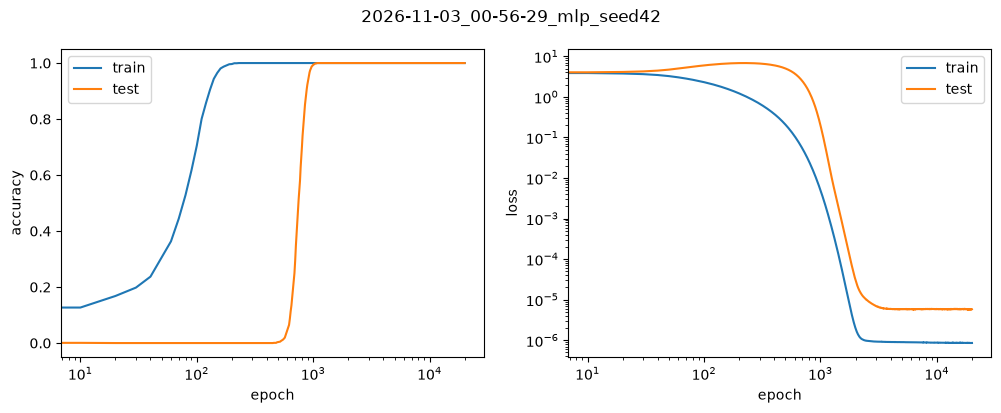

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

RUNS = Path("..") / "runs"
run_dir = sorted(RUNS.glob("*_mlp_seed42"))[-1]   # newest main run
df = pd.read_csv(run_dir / "metrics.csv")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

ax1.plot(df["epoch"], df["train_acc"], label="train")
ax1.plot(df["epoch"], df["test_acc"], label="test")
ax1.set_xscale("log")
ax1.set_xlabel("epoch")
ax1.set_ylabel("accuracy")
ax1.legend()

ax2.plot(df["epoch"], df["train_loss"], label="train")
ax2.plot(df["epoch"], df["test_loss"], label="test")
ax2.set_xscale("log")
ax2.set_yscale("log")
ax2.set_xlabel("epoch")
ax2.set_ylabel("loss")
ax2.legend()

plt.suptitle(run_dir.name)
plt.show()

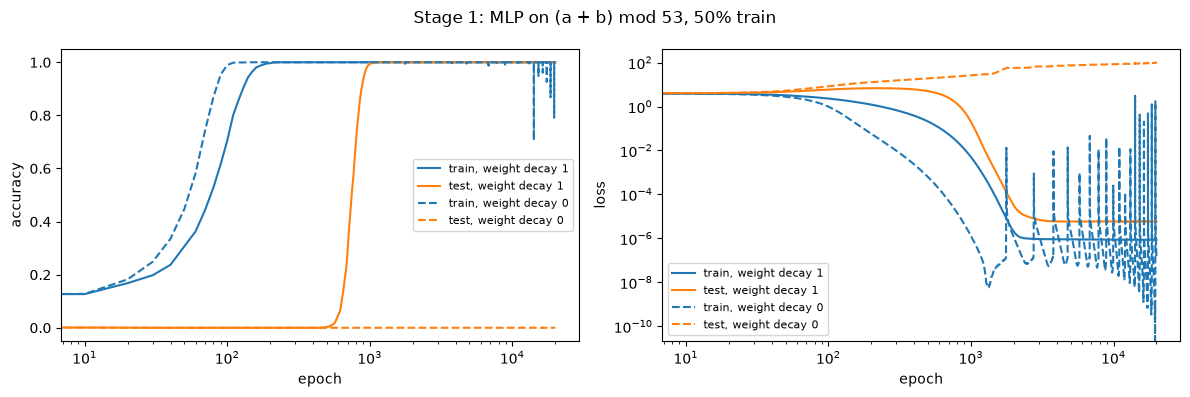

In [3]:
runs = {
    "weight decay 1": sorted(RUNS.glob("*_mlp_seed42"))[-1],
    "weight decay 0": sorted(RUNS.glob("*_mlp_wd0_seed42"))[-1],
}
styles = {"weight decay 1": "-", "weight decay 0": "--"}   # solid vs dashed

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

for label, run_dir in runs.items():
    df = pd.read_csv(run_dir / "metrics.csv")
    ls = styles[label]
    ax1.plot(df["epoch"], df["train_acc"], ls, color="C0", label=f"train, {label}")
    ax1.plot(df["epoch"], df["test_acc"], ls, color="C1", label=f"test, {label}")
    ax2.plot(df["epoch"], df["train_loss"], ls, color="C0", label=f"train, {label}")
    ax2.plot(df["epoch"], df["test_loss"], ls, color="C1", label=f"test, {label}")

ax1.set_xscale("log")
ax1.set_xlabel("epoch")
ax1.set_ylabel("accuracy")
ax1.legend(fontsize=8)

ax2.set_xscale("log")
ax2.set_yscale("log")
ax2.set_xlabel("epoch")
ax2.set_ylabel("loss")
ax2.legend(fontsize=8)

plt.suptitle("Stage 1: MLP on (a + b) mod 53, 50% train")
plt.tight_layout()

Path("figures").mkdir(exist_ok=True)
plt.savefig("figures/stage1_grokking_vs_control.png", dpi=200)
plt.show()